<a href="https://colab.research.google.com/github/Omkar-S-Nath/datascience/blob/main/Copy_of_flower_classifier.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🌸 Flower Image Classification Using CNN

## Artificial Intelligence / Machine Learning Project

### Project Overview

This project aims to develop an image classification model that can identify different types of flowers from an input image.

A Convolutional Neural Network (CNN) is trained using images of three flower categories:

- Rose 🌹
- Sunflower 🌻
- Tulip 🌷

After training, the model can classify a new flower image into one of these three categories.

## 1. Introduction

Image classification is an important application of Artificial Intelligence and Computer Vision. It involves training a machine learning model to recognize and classify images into predefined categories.

In this project, a Convolutional Neural Network (CNN) is used to classify flower images. The model learns visual features such as shapes, colors, edges, textures, and patterns from the training images.

The trained model can then be used to predict the category of a new flower image.

## 2. Problem Statement

Identifying flower species from images manually can be difficult when the flowers have similar visual characteristics.

The objective of this project is to develop a simple machine learning system that can automatically classify a flower image into one of three categories: Rose, Sunflower, or Tulip.

## 3. Objectives

The main objectives of this project are:

- To understand image classification using machine learning.
- To prepare and preprocess flower images.
- To build a Convolutional Neural Network (CNN).
- To train the model using flower images.
- To evaluate the accuracy of the trained model.
- To predict the category of a new flower image.

In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import os

from tensorflow.keras import layers, models

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.20.0


In [ ]:
print("GPU Available:")
print(tf.config.list_physical_devices('GPU'))

GPU Available:
[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 4. Dataset

The dataset contains images of different types of flowers.

For this project, we will use three flower categories:

- Rose 🌹
- Sunflower 🌻
- Tulip 🌷

The images will be organized into separate folders according to their flower category.

In [ ]:
import urllib.request
import os

url = "https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz"

file_path = "/content/flower_photos.tgz"

urllib.request.urlretrieve(url, file_path)

print("Dataset downloaded successfully!")
print("File exists:", os.path.exists(file_path))

Dataset downloaded successfully!
File exists: True


## 5. Extracting the Dataset

The downloaded dataset is compressed in a `.tgz` file. It is extracted so that the individual flower images can be accessed and organized for training.

In [ ]:
import tarfile

extract_path = "/content"

with tarfile.open(file_path, "r:gz") as tar:
    tar.extractall(path=extract_path)

print("Dataset extracted successfully!")

/tmp/ipykernel_2747/1270331065.py:6: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extractall(path=extract_path)


Dataset extracted successfully!


In [ ]:
data_dir = "/content/flower_photos"

print("Folders in the dataset:")

for folder in os.listdir(data_dir):
    print(folder)

Folders in the dataset:
tulips
LICENSE.txt
daisy
sunflowers
roses
dandelion


## 6. Selecting the Required Flower Classes

The original dataset contains five flower categories. To keep this project simple, only three categories are selected:

- Rose
- Sunflower
- Tulip

The selected images are copied into a new dataset directory.

In [ ]:
import shutil

selected_classes = ["roses", "sunflowers", "tulips"]

simple_data_dir = "/content/flower_dataset"

os.makedirs(simple_data_dir, exist_ok=True)

for flower_class in selected_classes:
    source = os.path.join(data_dir, flower_class)
    destination = os.path.join(simple_data_dir, flower_class)

    shutil.copytree(source, destination, dirs_exist_ok=True)

print("Three flower classes prepared successfully!")

Three flower classes prepared successfully!


In [ ]:
for flower_class in selected_classes:
    folder = os.path.join(simple_data_dir, flower_class)
    images = os.listdir(folder)
    print(f"{flower_class}: {len(images)} images")

roses: 641 images
sunflowers: 699 images
tulips: 799 images


## 7. Loading the Dataset

The prepared flower images are loaded using TensorFlow's image dataset utility.

The images are divided into training and validation sets. The training set is used to train the CNN model, while the validation set is used to evaluate the model on images that it has not seen during training.

In [ ]:
IMG_SIZE = 180
BATCH_SIZE = 32

train_dataset = tf.keras.utils.image_dataset_from_directory(
    simple_data_dir,
    validation_split=0.2,
    subset="training",
    seed=42,
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE
)

print("Training dataset loaded successfully!")

Found 2139 files belonging to 3 classes.
Using 1712 files for training.
Training dataset loaded successfully!


In [ ]:
validation_dataset = tf.keras.utils.image_dataset_from_directory(
    simple_data_dir,
    validation_split=0.2,
    subset="validation",
    seed=42,
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE
)

print("Validation dataset loaded successfully!")

Found 2139 files belonging to 3 classes.
Using 427 files for validation.
Validation dataset loaded successfully!


In [ ]:
class_names = train_dataset.class_names

print("Flower classes:")
print(class_names)

Flower classes:
['roses', 'sunflowers', 'tulips']


## 8. Visualizing the Dataset

A few sample images from the training dataset are displayed below.

This helps us visually inspect the images before training the machine learning model.

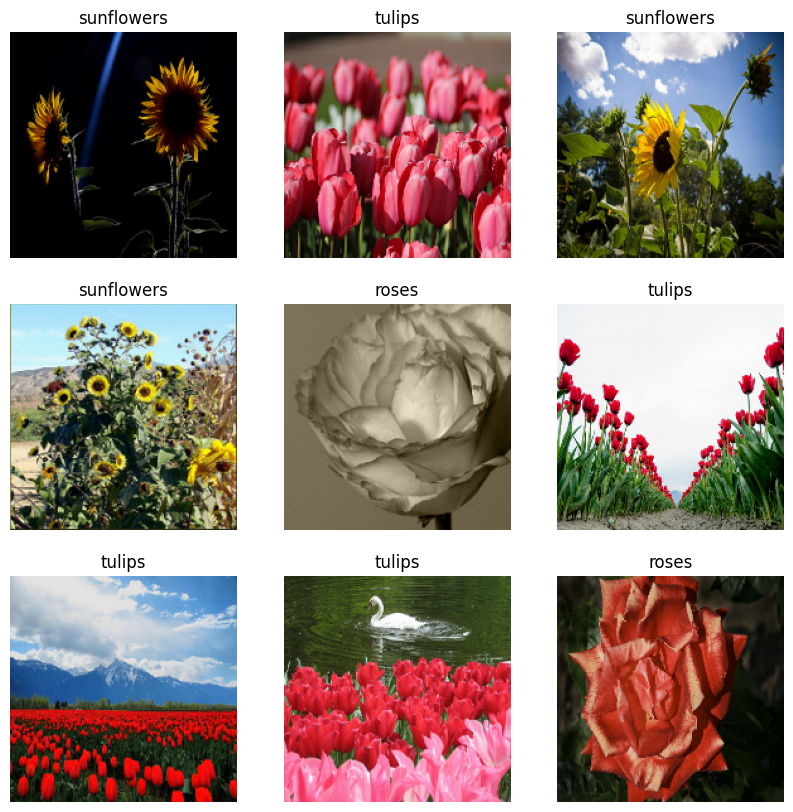

In [ ]:
plt.figure(figsize=(10, 10))

for images, labels in train_dataset.take(1):
    for i in range(9):
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[labels[i]])
        plt.axis("off")

plt.show()

## 9. Image Normalization

Image pixel values normally range from 0 to 255.

To make the training process more efficient, the pixel values are rescaled to the range 0 to 1.

This normalization helps the neural network learn more effectively.

In [ ]:
normalization_layer = layers.Rescaling(1./255)

train_dataset = train_dataset.map(
    lambda x, y: (normalization_layer(x), y)
)

validation_dataset = validation_dataset.map(
    lambda x, y: (normalization_layer(x), y)
)

print("Image normalization completed!")

Image normalization completed!


In [ ]:
AUTOTUNE = tf.data.AUTOTUNE

train_dataset = train_dataset.cache().shuffle(1000).prefetch(
    buffer_size=AUTOTUNE
)

validation_dataset = validation_dataset.cache().prefetch(
    buffer_size=AUTOTUNE
)

print("Dataset optimization completed!")

Dataset optimization completed!


## 10. Building the Convolutional Neural Network (CNN)

A Convolutional Neural Network (CNN) is used for this image classification task.

CNNs are particularly useful for image recognition because they can automatically learn important visual features from images, such as:

- Edges
- Shapes
- Colors
- Textures
- Patterns

The model will learn these features from the training images and use them to classify an image as a Rose, Sunflower, or Tulip.

In [ ]:
model = models.Sequential([

    # First convolutional layer
    layers.Conv2D(
        32,
        (3, 3),
        activation='relu',
        input_shape=(IMG_SIZE, IMG_SIZE, 3)
    ),
    layers.MaxPooling2D((2, 2)),

    # Second convolutional layer
    layers.Conv2D(
        64,
        (3, 3),
        activation='relu'
    ),
    layers.MaxPooling2D((2, 2)),

    # Third convolutional layer
    layers.Conv2D(
        128,
        (3, 3),
        activation='relu'
    ),
    layers.MaxPooling2D((2, 2)),

    # Convert feature maps into a single vector
    layers.Flatten(),

    # Fully connected layer
    layers.Dense(128, activation='relu'),

    # Reduce overfitting
    layers.Dropout(0.5),

    # Output layer - 3 flower classes
    layers.Dense(3, activation='softmax')
])

print("CNN model created successfully!")

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


CNN model created successfully!


## 11. CNN Model Architecture

The model architecture is displayed below to understand the different layers used for image classification.

In [ ]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 178, 178, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 89, 89, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 87, 87, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 43, 43, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 41, 41, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 20, 20, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 51200)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     6,553,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,647,363 (25.36 MB)

 Trainable params: 6,647,363 (25.36 MB)

 Non-trainable params: 0 (0.00 B)

## 12. Compiling the Model

The CNN model is compiled using:

- Adam optimizer for updating the model's weights.
- Sparse categorical cross-entropy as the loss function.
- Accuracy as the evaluation metric.

The optimizer helps the model learn from its errors during training.

In [ ]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("Model compiled successfully!")

Model compiled successfully!


## 13. Training the CNN Model

The CNN is trained using the training dataset.

During each epoch, the model processes the training images, compares its predictions with the actual labels, and adjusts its internal weights to improve its predictions.

The validation dataset is used to monitor the model's performance on unseen images.

In [ ]:
history = model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=10
)

Epoch 1/10
54/54 ━━━━━━━━━━━━━━━━━━━━ 17s 143ms/step - accuracy: 0.5485 - loss: 0.9467 - val_accuracy: 0.6393 - val_loss: 0.7174
Epoch 2/10
54/54 ━━━━━━━━━━━━━━━━━━━━ 2s 34ms/step - accuracy: 0.6729 - loss: 0.7180 - val_accuracy: 0.6464 - val_loss: 0.7338
Epoch 3/10
54/54 ━━━━━━━━━━━━━━━━━━━━ 2s 34ms/step - accuracy: 0.7126 - loss: 0.6519 - val_accuracy: 0.7049 - val_loss: 0.6512
Epoch 4/10
54/54 ━━━━━━━━━━━━━━━━━━━━ 2s 34ms/step - accuracy: 0.7459 - loss: 0.5722 - val_accuracy: 0.6862 - val_loss: 0.6604
Epoch 5/10
54/54 ━━━━━━━━━━━━━━━━━━━━ 2s 36ms/step - accuracy: 0.7944 - loss: 0.4776 - val_accuracy: 0.7026 - val_loss: 0.6804
Epoch 6/10
54/54 ━━━━━━━━━━━━━━━━━━━━ 2s 35ms/step - accuracy: 0.8265 - loss: 0.4332 - val_accuracy: 0.7424 - val_loss: 0.5698
Epoch 7/10
54/54 ━━━━━━━━━━━━━━━━━━━━ 2s 34ms/step - accuracy: 0.8709 - loss: 0.3185 - val_accuracy: 0.7424 - val_loss: 0.6898
Epoch 8/10
54/54 ━━━━━━━━━━━━━━━━━━━━ 2s 34ms/step - accuracy: 0.9013 - loss: 0.2761 - val_accuracy: 0.7494 -

## 14. Model Evaluation

After training, the model is evaluated using the validation dataset.

The validation dataset contains images that were not used during training. This helps us understand how well the model performs on previously unseen flower images.

The main evaluation metrics are:

- Accuracy
- Loss

In [ ]:
loss, accuracy = model.evaluate(validation_dataset)

print("Validation Loss:", loss)
print("Validation Accuracy:", accuracy)
print("Validation Accuracy (%):", round(accuracy * 100, 2), "%")

14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.7494 - loss: 0.8116
Validation Loss: 0.8116330504417419
Validation Accuracy: 0.7494145035743713
Validation Accuracy (%): 74.94 %


## 15. Training and Validation Accuracy

The following graph shows the training accuracy and validation accuracy across the different training epochs.

Training accuracy shows how well the model performs on the images used for training, while validation accuracy shows how well it performs on unseen images.

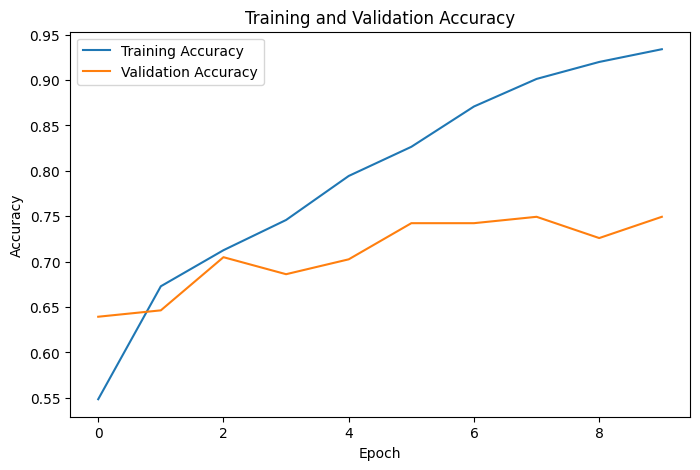

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    history.history['accuracy'],
    label='Training Accuracy'
)

plt.plot(
    history.history['val_accuracy'],
    label='Validation Accuracy'
)

plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Training and Validation Accuracy')

plt.legend()
plt.show()

## 16. Training and Validation Loss

Loss represents how far the model's predictions are from the correct answers.

A lower loss generally indicates that the model is making better predictions.

The graph below shows how the training and validation loss change during training.

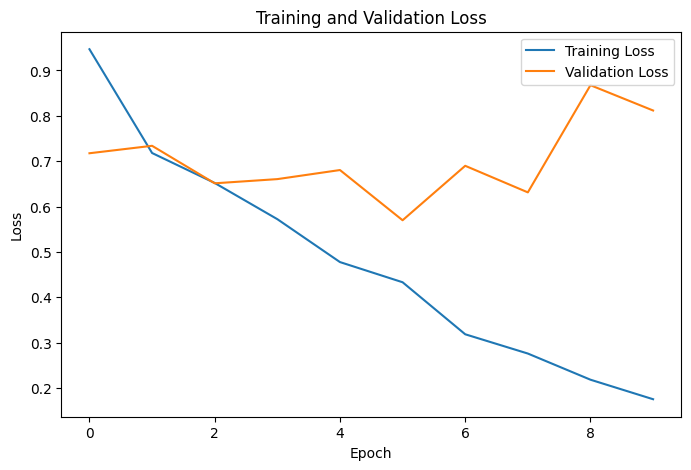

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    history.history['loss'],
    label='Training Loss'
)

plt.plot(
    history.history['val_loss'],
    label='Validation Loss'
)

plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training and Validation Loss')

plt.legend()
plt.show()

## 17. Saving the Trained Model

The trained CNN model is saved so that it can be reused later without having to train it again.

The saved model can be loaded and used to classify new flower images.

In [ ]:
model.save("/content/flower_classifier.keras")

print("Model saved successfully!")

Model saved successfully!


## 18. Testing the Model with a New Image

After training the CNN model, it can be tested using a new flower image that was not part of the training dataset.

The user can upload an image, and the model will predict whether the image is a Rose, Sunflower, or Tulip.

In [ ]:
from google.colab import files

uploaded = files.upload()

print("Image uploaded successfully!")

Saving OIP (1).jpeg to OIP (1).jpeg
Image uploaded successfully!


## 19. Flower Prediction

The uploaded image is resized to the same dimensions used during model training.

The image is then normalized and passed to the trained CNN model.

The model produces probabilities for the three flower classes. The class with the highest probability is selected as the final prediction.

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
Predicted Flower: sunflowers
Confidence: 99.88 %


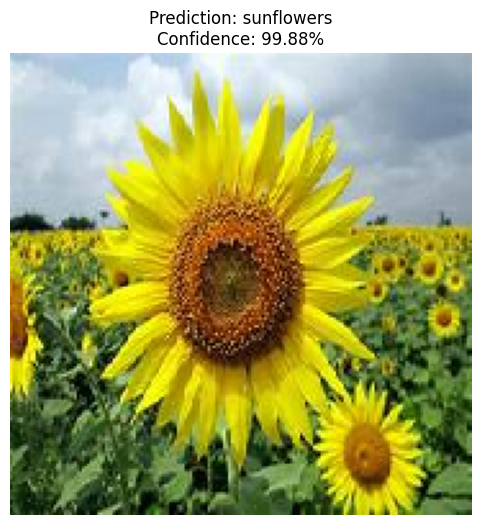

In [ ]:
from tensorflow.keras.utils import load_img, img_to_array

# Get the uploaded filename
filename = list(uploaded.keys())[0]

# Load and resize the image
image = load_img(
    filename,
    target_size=(IMG_SIZE, IMG_SIZE)
)

# Convert image to array
image_array = img_to_array(image)

# Normalize pixel values
image_array = image_array / 255.0

# Add batch dimension
image_array = np.expand_dims(image_array, axis=0)

# Make prediction
predictions = model.predict(image_array)

# Find the class with highest probability
predicted_index = np.argmax(predictions[0])

predicted_class = class_names[predicted_index]

confidence = predictions[0][predicted_index] * 100

# Display result
print("Predicted Flower:", predicted_class)
print("Confidence:", round(confidence, 2), "%")

# Display image
plt.figure(figsize=(6, 6))
plt.imshow(image)
plt.axis("off")
plt.title(
    f"Prediction: {predicted_class}\n"
    f"Confidence: {confidence:.2f}%"
)
plt.show()

## 20. Prediction Probabilities

The model produces a probability for each flower category. These probabilities indicate how confident the model is about each possible class.

In [ ]:
for i, class_name in enumerate(class_names):
    probability = predictions[0][i] * 100
    print(f"{class_name}: {probability:.2f}%")

roses: 0.00%
sunflowers: 99.88%
tulips: 0.12%


## 21. Prediction Probability Visualization

The prediction probabilities for each flower category are visualized using a bar chart.

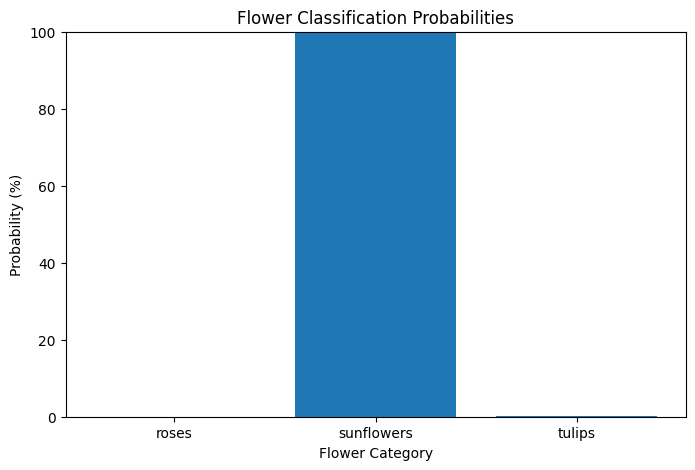

In [ ]:
probabilities = predictions[0] * 100

plt.figure(figsize=(8, 5))

plt.bar(class_names, probabilities)

plt.xlabel("Flower Category")
plt.ylabel("Probability (%)")
plt.title("Flower Classification Probabilities")

plt.ylim(0, 100)
plt.show()

## 22. Conclusion

In this project, a Convolutional Neural Network was developed to classify flower images into three categories: Rose, Sunflower, and Tulip.

The images were preprocessed and divided into training and validation datasets. A CNN model was then trained to learn visual features from the flower images.

The model was evaluated using validation data, and its accuracy was measured. Finally, a new flower image was uploaded and classified by the trained model.

This project demonstrates how Artificial Intelligence and Computer Vision can be used for automatic image classification.